<a href="https://colab.research.google.com/github/janhavipatkar854/CSL701-CS42-Machine-Learning-Lab/blob/main/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : janhavi patkar

Batch : cs 03


Roll Number : cs 42



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:

# Task 1: Import Libraries and Load Dataset

# Step 1: Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Step 2: Load the Palmer Penguins Extended dataset
df = pd.read_csv('/content/palmerpenguins_extended.csv')

# Step 3: Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Step 4: Display dataset dimensions
print("\nDataset Dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Step 5: Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Step 6: Display dataset information
print("\nDataset Information:")
df.info()


First five rows of the dataset:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021



Dataset Dimensions:
Rows: 3430
Columns: 11

Column Names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3430 entries, 0 to 3429
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            3430 non-null   object 
 1   island             3430 non-null   object 
 2   bill_length_mm     3430 non-null   float64
 3   bill_depth_mm      3430 non-null   float64
 4   flipper_length_mm  3430 non-null   float64
 5   body_mass_g        3430 non-null   float64
 6   sex                3430 non-null   object 
 7   diet               3430 non-null   object 
 8   life_stage         3430 non-null   object 
 9   health_metrics     3430 non-null   object 
 10  year               3430 non-null   int64  
dtypes: float64(4), int64(1), object(6)


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:

# Task 2: Select Features and Target & Preprocess

# Step 1: Import required libraries
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Step 2: Clean column names
df.columns = df.columns.str.strip()

# Step 3: Identify the required features and target
features = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

# Handle common alternative column names
column_mapping = {
    'culmen_length_mm': ['culmen_length_mm', 'bill_length_mm'],
    'culmen_depth_mm': ['culmen_depth_mm', 'bill_depth_mm'],
    'flipper_length_mm': ['flipper_length_mm'],
    'body_mass_g': ['body_mass_g'],
    'species': ['species']
}

# Find matching columns in the dataset
selected_features = []

for feature in features:
    match = next(
        (col for col in column_mapping[feature] if col in df.columns),
        None
    )
    if match is None:
        raise ValueError(
            f"Feature '{feature}' not found. Available columns: {df.columns.tolist()}"
        )
    selected_features.append(match)

target_col = next(
    (col for col in column_mapping['species'] if col in df.columns),
    None
)

if target_col is None:
    raise ValueError(
        f"Target column 'species' not found. Available columns: {df.columns.tolist()}"
    )

# Step 4: Select features and target
X = df[selected_features].copy()
y = df[target_col].copy()

# Step 5: Convert features to numeric and handle missing/invalid values
X = X.apply(pd.to_numeric, errors='coerce')

# Replace infinite values with NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Impute missing feature values with their median
X = X.fillna(X.median())

# Remove rows where the target label is missing
valid_rows = y.notna()
X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].reset_index(drop=True)

# Step 6: Encode categorical target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y.astype(str))

# Step 7: Display results
print("Selected Features:", selected_features)
print("\nFeature Matrix Shape:", X.shape)
print("Target Vector Shape:", y_encoded.shape)

print("\nFirst five feature rows:")
display(X.head())

print("\nSpecies Class Distribution:")
print(y.value_counts())

print("\nSpecies Encoding:")
for class_name, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{class_name} -> {encoded_value}")

print("\nMissing Values After Preprocessing:")
print(X.isnull().sum())


Selected Features: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

Feature Matrix Shape: (3430, 4)
Target Vector Shape: (3430,)

First five feature rows:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,53.4,17.8,219.0,5687.0
1,49.3,18.1,245.0,6811.0
2,55.7,16.6,226.0,5388.0
3,38.0,15.6,221.0,6262.0
4,60.7,17.9,177.0,4811.0



Species Class Distribution:
species
Adelie       1560
Gentoo       1247
Chinstrap     623
Name: count, dtype: int64

Species Encoding:
Adelie -> 0
Chinstrap -> 1
Gentoo -> 2

Missing Values After Preprocessing:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [3]:

# Task 3: Split the Data

# Import required library
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Display the shapes of the resulting datasets
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Display class distribution in training and testing sets
print("\nTraining Set Class Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting Set Class Distribution:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nData splitting completed successfully!")


Training Features Shape: (2744, 4)
Testing Features Shape: (686, 4)
Training Target Shape: (2744,)
Testing Target Shape: (686,)

Training Set Class Distribution:
0    1248
1     498
2     998
Name: count, dtype: int64

Testing Set Class Distribution:
0    312
1    125
2    249
Name: count, dtype: int64

Data splitting completed successfully!


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [4]:

# Task 4: Implement CART Classifier

# Step 1: Import required library
from sklearn.tree import DecisionTreeClassifier

# Step 2: Create the CART classifier
cart_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Step 3: Train the model
cart_model.fit(X_train, y_train)

print("CART Classifier trained successfully!")

# Step 4: Make predictions on the test data
y_pred = cart_model.predict(X_test)

# Step 5: Display predictions
print("\nActual Test Labels (first 10):")
print(y_test[:10])

print("\nPredicted Labels (first 10):")
print(y_pred[:10])

print("\nNumber of test samples:", len(y_test))
print("Number of predictions:", len(y_pred))


CART Classifier trained successfully!

Actual Test Labels (first 10):
[0 2 0 0 0 2 1 0 2 0]

Predicted Labels (first 10):
[2 2 0 0 2 2 1 0 0 0]

Number of test samples: 686
Number of predictions: 686


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Classifier Evaluation
--------------------------
Accuracy: 0.4519
Accuracy Percentage: 45.19%

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]


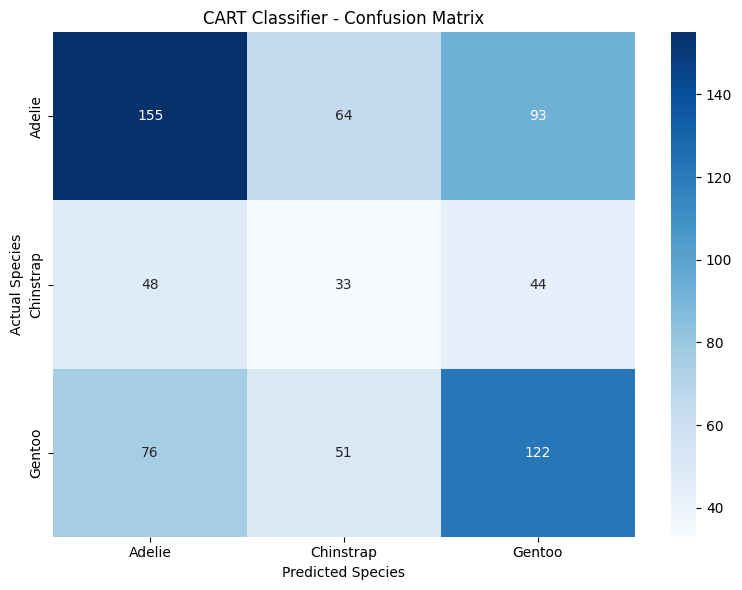


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



In [5]:

# Task 5: Evaluate CART Model

# Step 1: Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Step 2: Calculate classification accuracy
accuracy = accuracy_score(y_test, y_pred)

print("CART Classifier Evaluation")
print("--------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

# Step 3: Generate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(label_encoder.classes_))
)

print("\nConfusion Matrix:")
print(cm)

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("CART Classifier - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

# Step 4: Generate the classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


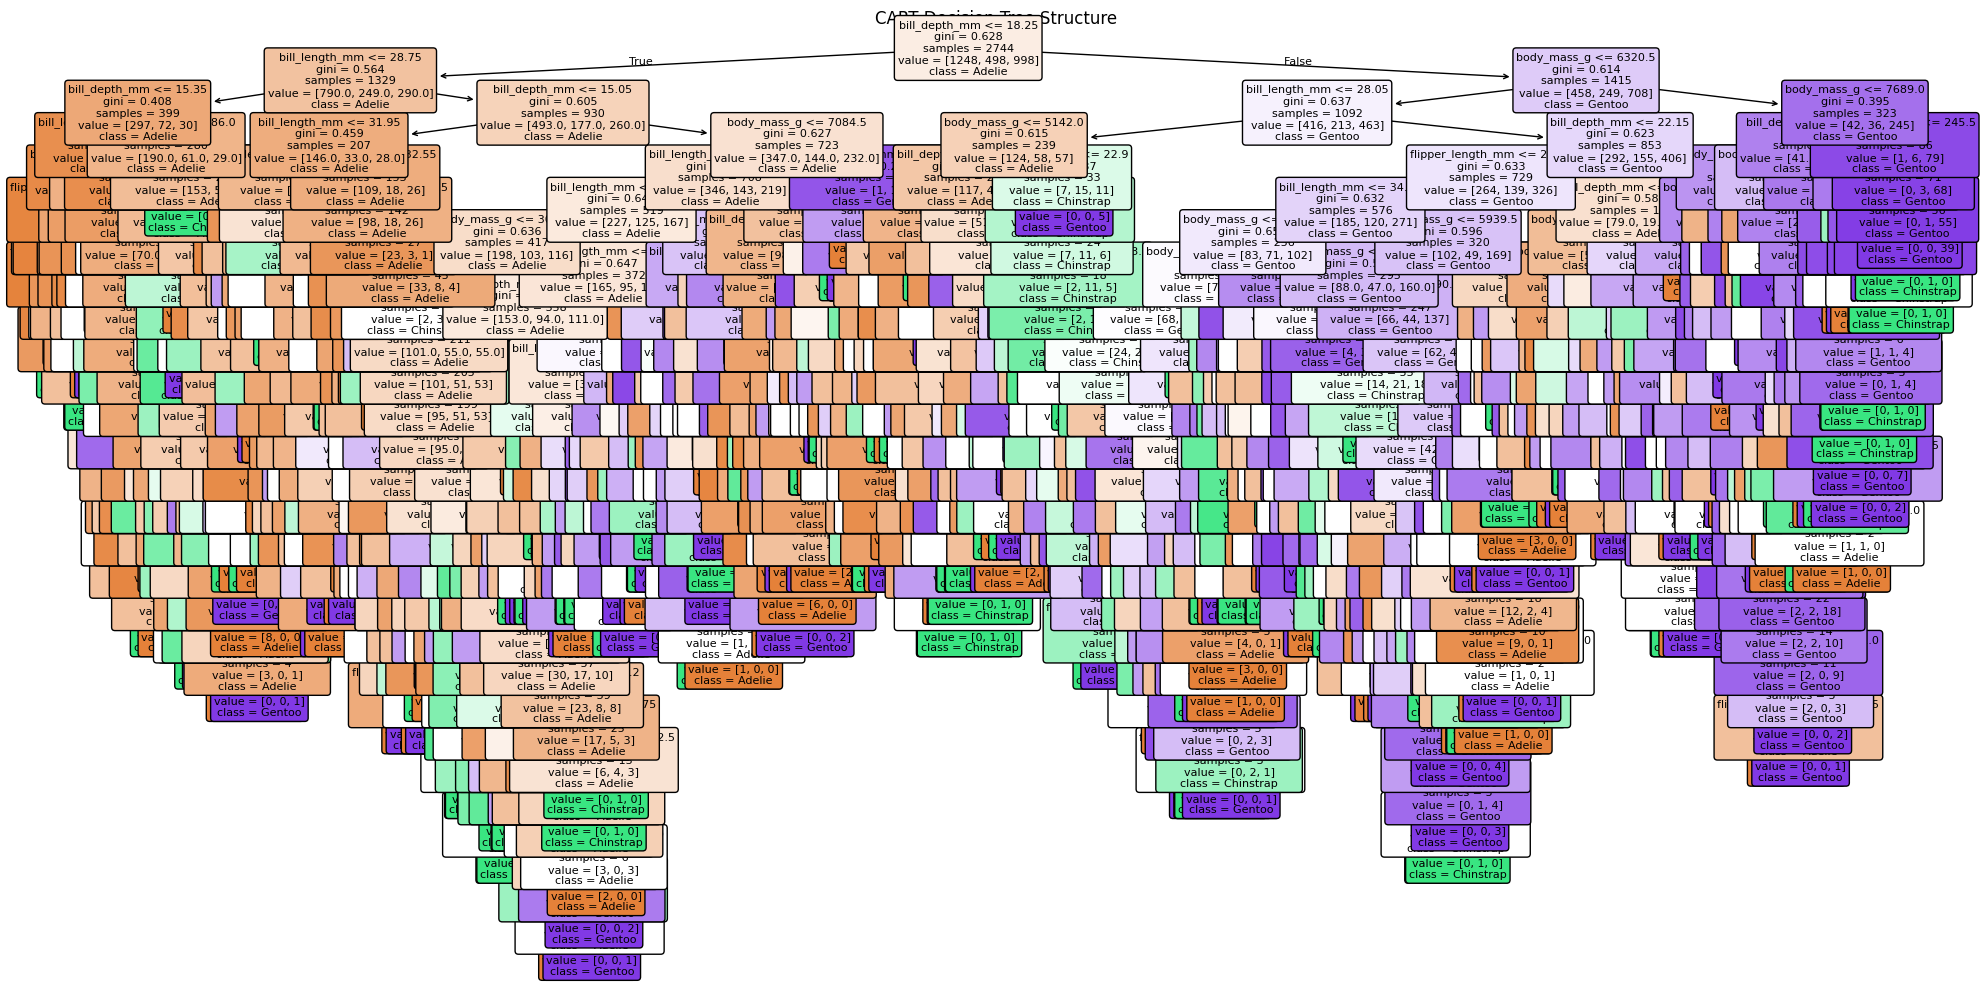

2D Decision Tree trained successfully!
Selected features: bill_length_mm and flipper_length_mm


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


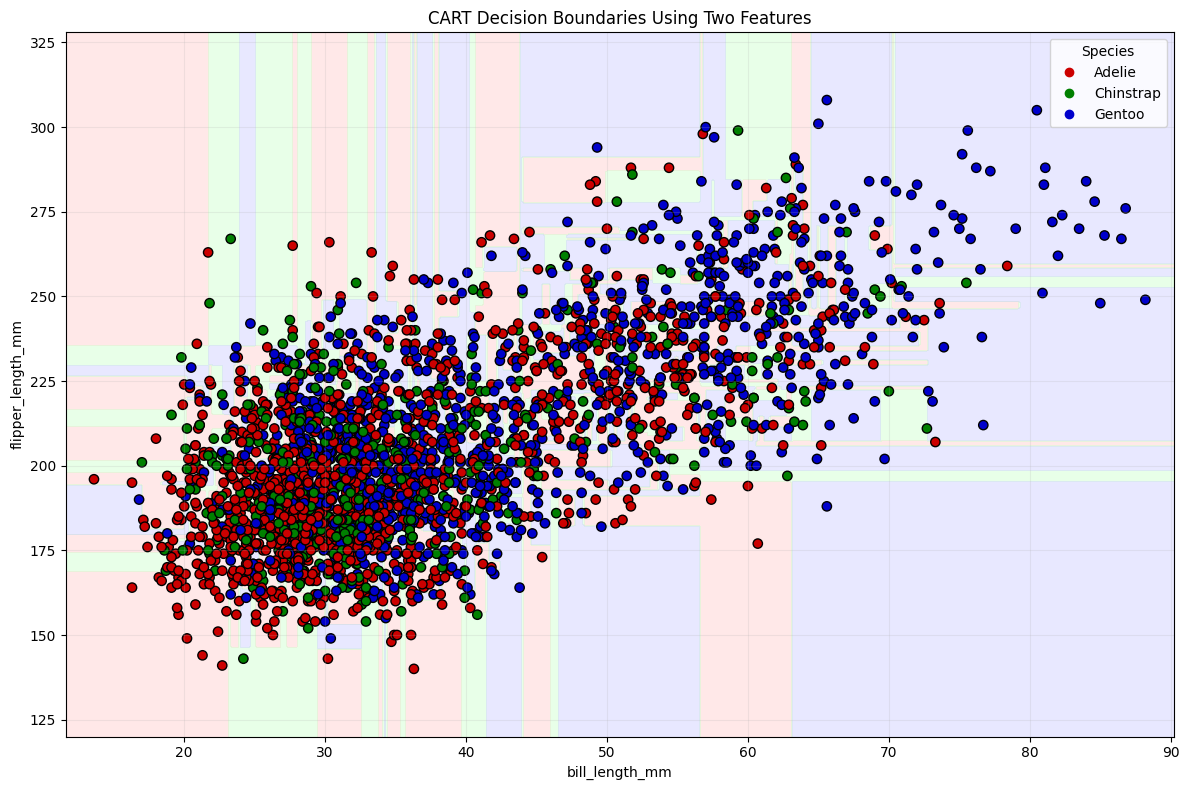

In [6]:

# Task 6: Visualize Decision Tree & Decision Boundary

import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, DecisionTreeClassifier
from matplotlib.colors import ListedColormap

# --------------------------------------------------
# Part 1: Visualize the trained CART decision tree
# --------------------------------------------------

plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=X.columns.tolist(),
    class_names=label_encoder.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree Structure")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Part 2: Select 2-D features
# --------------------------------------------------

feature_1 = 'culmen_length_mm'
feature_2 = 'flipper_length_mm'

# Support common alternative column names
if feature_1 not in X.columns and 'bill_length_mm' in X.columns:
    feature_1 = 'bill_length_mm'

if feature_2 not in X.columns:
    raise ValueError(
        f"{feature_2} not found. Available features: {X.columns.tolist()}"
    )

if feature_1 not in X.columns:
    raise ValueError(
        f"Culmen/bill length feature not found. Available features: {X.columns.tolist()}"
    )

X_2d = X[[feature_1, feature_2]].copy()

# Split the same 2D features into training and testing sets
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)


# --------------------------------------------------
# Part 3: Train a decision tree using 2-D features
# --------------------------------------------------

cart_2d = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

cart_2d.fit(X_train_2d, y_train_2d)

print("2D Decision Tree trained successfully!")
print("Selected features:", feature_1, "and", feature_2)


# --------------------------------------------------
# Part 4: Create the decision boundary grid
# --------------------------------------------------

x_min, x_max = X_2d[feature_1].min() - 2, X_2d[feature_1].max() + 2
y_min, y_max = X_2d[feature_2].min() - 20, X_2d[feature_2].max() + 20

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = cart_2d.predict(grid).reshape(xx.shape)


# --------------------------------------------------
# Part 5: Plot decision boundaries and data points
# --------------------------------------------------

cmap_background = ListedColormap(['#FFCCCC', '#CCFFCC', '#CCCCFF'])
cmap_points = ListedColormap(['#CC0000', '#008000', '#0000CC'])

plt.figure(figsize=(12, 8))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.45,
    cmap=cmap_background,
    levels=np.arange(len(label_encoder.classes_) + 1) - 0.5
)

scatter = plt.scatter(
    X_train_2d[feature_1],
    X_train_2d[feature_2],
    c=y_train_2d,
    cmap=cmap_points,
    edgecolors='black',
    s=45,
    label='Training samples'
)

plt.xlabel(feature_1)
plt.ylabel(feature_2)
plt.title("CART Decision Boundaries Using Two Features")
plt.legend()
plt.grid(alpha=0.2)

# Species legend
handles, _ = scatter.legend_elements()
plt.legend(
    handles,
    label_encoder.classes_.tolist(),
    title="Species",
    loc="best"
)

plt.tight_layout()
plt.show()


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression Accuracy: 52.62 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


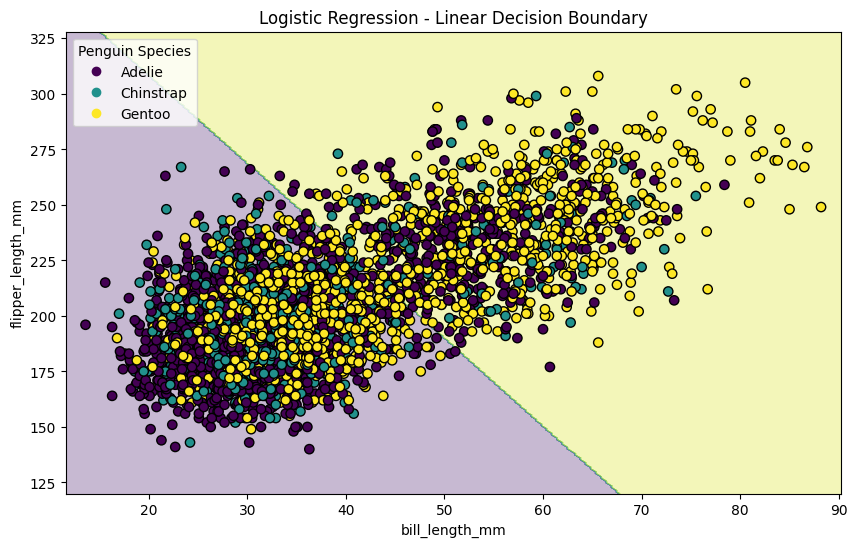

In [7]:

# Task 7: Normal Linear Classification Boundary

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

# Select the same two features used in Task 6
feature_1 = 'culmen_length_mm'
feature_2 = 'flipper_length_mm'

# Handle alternative column name if required
if feature_1 not in X.columns and 'bill_length_mm' in X.columns:
    feature_1 = 'bill_length_mm'

X_2d = X[[feature_1, feature_2]].copy()

# Split the data using the same random state
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_2d, y_train_2d)

# Calculate accuracy
y_pred_logistic = logistic_model.predict(X_test_2d)
accuracy = logistic_model.score(X_test_2d, y_test_2d)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

# Create a mesh grid for the decision boundary
x_min, x_max = X_2d[feature_1].min() - 2, X_2d[feature_1].max() + 2
y_min, y_max = X_2d[feature_2].min() - 20, X_2d[feature_2].max() + 20

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict classes for each grid point
grid = np.c_[xx.ravel(), yy.ravel()]
Z = logistic_model.predict(grid)
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(10, 6))

plt.contourf(
    xx, yy, Z,
    alpha=0.3,
    cmap='viridis'
)

# Plot actual data points
scatter = plt.scatter(
    X_2d[feature_1],
    X_2d[feature_2],
    c=y_encoded,
    cmap='viridis',
    edgecolors='black',
    s=45
)

plt.xlabel(feature_1)
plt.ylabel(feature_2)
plt.title('Logistic Regression - Linear Decision Boundary')

# Add species names to the legend
handles, _ = scatter.legend_elements()
plt.legend(
    handles,
    label_encoder.classes_,
    title='Penguin Species'
)

plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


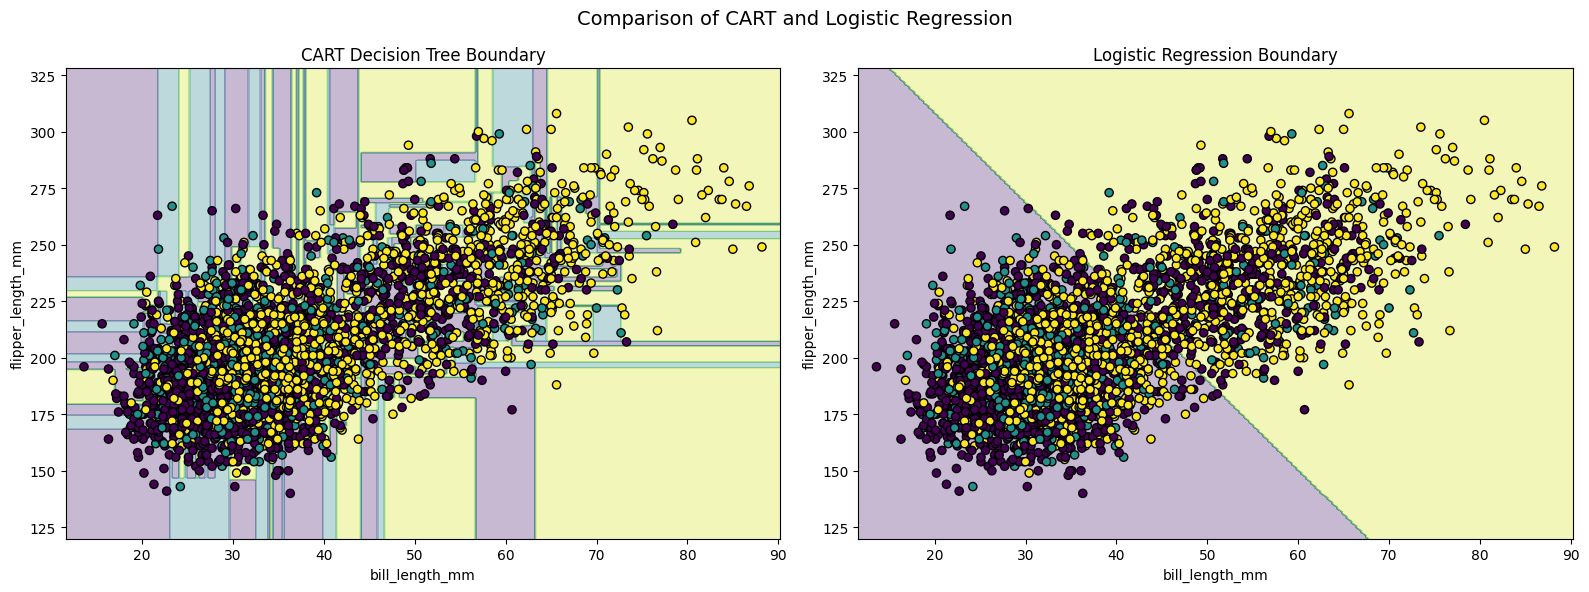

CART Decision Tree Accuracy: 43.88 %
Logistic Regression Accuracy: 52.62 %


In [8]:

# Task 8: Compare CART and Normal Linear Boundary

import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Select the same two features used in Tasks 6 and 7
feature_1 = 'culmen_length_mm'
feature_2 = 'flipper_length_mm'

# Handle alternative feature name
if feature_1 not in X.columns and 'bill_length_mm' in X.columns:
    feature_1 = 'bill_length_mm'

X_2d = X[[feature_1, feature_2]].copy()

# Split the data consistently
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Train CART Decision Tree
cart_2d = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)
cart_2d.fit(X_train_2d, y_train_2d)

# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_2d, y_train_2d)

# Create mesh grid
x_min = X_2d[feature_1].min() - 2
x_max = X_2d[feature_1].max() + 2
y_min = X_2d[feature_2].min() - 20
y_max = X_2d[feature_2].max() + 20

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Predict decision regions
Z_cart = cart_2d.predict(grid).reshape(xx.shape)
Z_logistic = logistic_model.predict(grid).reshape(xx.shape)

# Plot side-by-side decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CART Decision Tree plot
axes[0].contourf(
    xx, yy, Z_cart,
    alpha=0.3,
    cmap='viridis'
)
axes[0].scatter(
    X_2d[feature_1],
    X_2d[feature_2],
    c=y_encoded,
    cmap='viridis',
    edgecolors='black',
    s=35
)
axes[0].set_title('CART Decision Tree Boundary')
axes[0].set_xlabel(feature_1)
axes[0].set_ylabel(feature_2)

# Logistic Regression plot
axes[1].contourf(
    xx, yy, Z_logistic,
    alpha=0.3,
    cmap='viridis'
)
axes[1].scatter(
    X_2d[feature_1],
    X_2d[feature_2],
    c=y_encoded,
    cmap='viridis',
    edgecolors='black',
    s=35
)
axes[1].set_title('Logistic Regression Boundary')
axes[1].set_xlabel(feature_1)
axes[1].set_ylabel(feature_2)

plt.suptitle('Comparison of CART and Logistic Regression', fontsize=14)
plt.tight_layout()
plt.show()

# Compare test accuracy
cart_accuracy = cart_2d.score(X_test_2d, y_test_2d)
logistic_accuracy = logistic_model.score(X_test_2d, y_test_2d)

print("CART Decision Tree Accuracy:",
      round(cart_accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

1. ACCURACY COMPARISON
CART Decision Tree Accuracy: 0.4388 (43.88%)
Logistic Regression Accuracy: 0.5262 (52.62%)


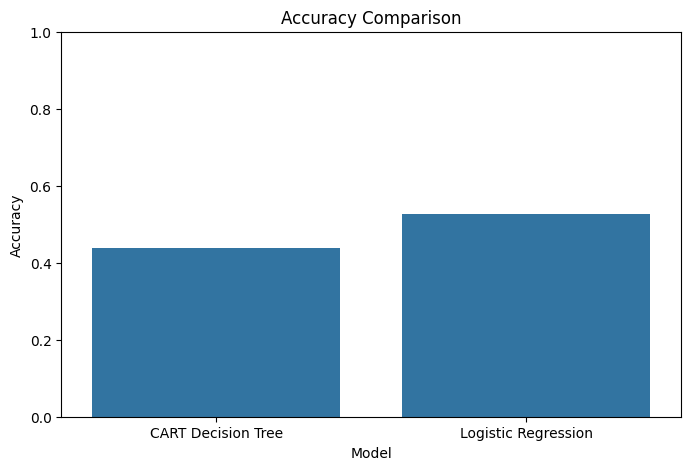


2. CONFUSION MATRICES

CART Decision Tree Confusion Matrix:
[[156  52 104]
 [ 55  31  39]
 [ 83  52 114]]

Logistic Regression Confusion Matrix:
[[245   0  67]
 [102   0  23]
 [133   0 116]]


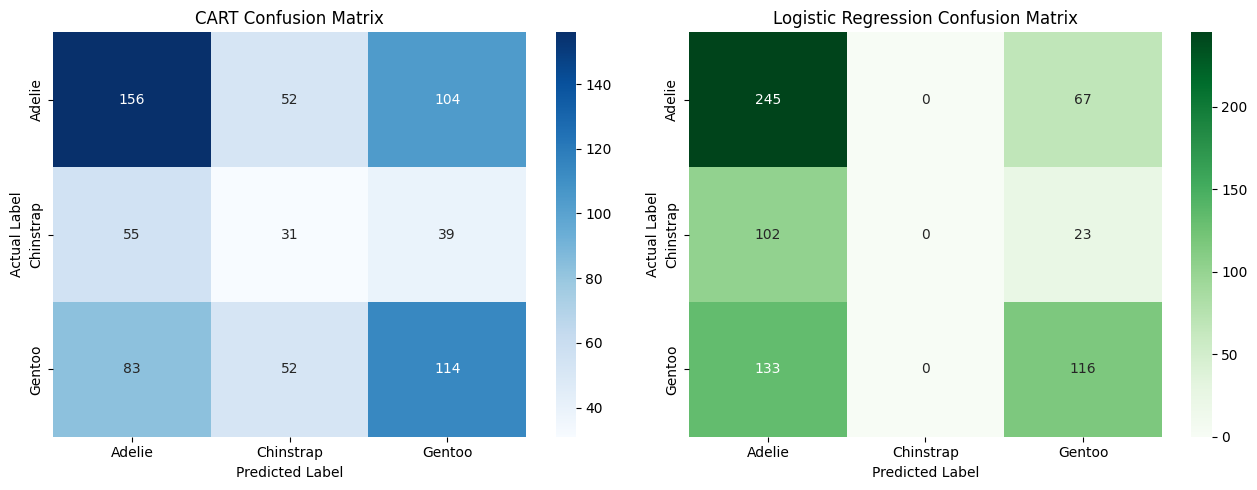


3. CLASSIFICATION REPORTS

CART Decision Tree Classification Report:
              precision    recall  f1-score   support

      Adelie       0.53      0.50      0.51       312
   Chinstrap       0.23      0.25      0.24       125
      Gentoo       0.44      0.46      0.45       249

    accuracy                           0.44       686
   macro avg       0.40      0.40      0.40       686
weighted avg       0.44      0.44      0.44       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686



In [9]:

# Task 9: Compare Performance
# CART Classifier vs Logistic Regression

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Train-set and test-set predictions
y_pred_cart = cart_2d.predict(X_test_2d)
y_pred_logistic = logistic_model.predict(X_test_2d)

# Calculate accuracy
cart_accuracy = accuracy_score(y_test_2d, y_pred_cart)
logistic_accuracy = accuracy_score(y_test_2d, y_pred_logistic)

print("=" * 60)
print("1. ACCURACY COMPARISON")
print("=" * 60)

print(f"CART Decision Tree Accuracy: {cart_accuracy:.4f} "
      f"({cart_accuracy * 100:.2f}%)")

print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f} "
      f"({logistic_accuracy * 100:.2f}%)")

# Compare accuracy in a bar chart
accuracy_df = pd.DataFrame({
    'Model': ['CART Decision Tree', 'Logistic Regression'],
    'Accuracy': [cart_accuracy, logistic_accuracy]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=accuracy_df, x='Model', y='Accuracy')
plt.ylim(0, 1)
plt.title('Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()

# Class labels
class_names = label_encoder.classes_
class_labels = list(range(len(class_names)))

# Confusion matrices
cm_cart = confusion_matrix(
    y_test_2d, y_pred_cart, labels=class_labels
)

cm_logistic = confusion_matrix(
    y_test_2d, y_pred_logistic, labels=class_labels
)

print("\n" + "=" * 60)
print("2. CONFUSION MATRICES")
print("=" * 60)

print("\nCART Decision Tree Confusion Matrix:")
print(cm_cart)

print("\nLogistic Regression Confusion Matrix:")
print(cm_logistic)

# Plot confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm_cart,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)
axes[0].set_title('CART Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

# Classification reports
print("\n" + "=" * 60)
print("3. CLASSIFICATION REPORTS")
print("=" * 60)

print("\nCART Decision Tree Classification Report:")
print(classification_report(
    y_test_2d,
    y_pred_cart,
    labels=class_labels,
    target_names=class_names,
    zero_division=0
))

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test_2d,
    y_pred_logistic,
    labels=class_labels,
    target_names=class_names,
    zero_division=0
))


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.